# Day 5: Linear Regression and Scikit-learn Workflow
System 7 Internship | Week 2 | Aayla Zahid Butt

## Notes
- **Simple linear regression:** one feature, y = w*x + b. It fits the best straight line.
- **Multiple linear regression:** many features, y = w1*x1 + w2*x2 + ... + b. Each coefficient shows how much y changes when that feature increases by one unit and the others stay the same.
- **Regression vs classification:** regression predicts a number (price). Classification predicts a class (benign or malignant).

## Scikit-learn workflow
1. Load and clean the data
2. Separate X (features) and y (target)
3. Split into train, validation and test sets
4. Create the model, for example `model = LinearRegression()`
5. Train it with `model.fit(X_train, y_train)`
6. Predict with `model.predict(X_val)`
7. Evaluate with R2, MAE and RMSE

The house-price dataset is the same one created on Day 4.

In [1]:
import numpy as np
import pandas as pd

# create the house-price dataset (500 houses)
rng = np.random.default_rng(42)
n = 500
area = rng.normal(1800, 500, n).clip(500, 4000).round(0)
bedrooms = np.clip((area / 700 + rng.normal(0, 0.7, n)).round(), 1, 6).astype(int)
bathrooms = np.clip((bedrooms * 0.7 + rng.normal(0, 0.6, n)).round(), 1, 5).astype(int)
age = rng.integers(0, 50, n)
dist = rng.uniform(1, 25, n).round(1)
price = (35000 + 120 * area + 8000 * bedrooms + 12000 * bathrooms
         - 900 * age - 2500 * dist + rng.normal(0, 25000, n)).round(0)

df = pd.DataFrame(dict(area_sqft=area, bedrooms=bedrooms, bathrooms=bathrooms,
                       house_age=age, dist_city_km=dist, price=price))

# make a few values missing on purpose to practise cleaning
df.loc[rng.choice(n, 12, replace=False), 'house_age'] = np.nan
df.loc[rng.choice(n, 8, replace=False), 'dist_city_km'] = np.nan
df.to_csv('house_prices.csv', index=False)

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('house_prices.csv')

# fill missing values with the median
df['house_age'] = df['house_age'].fillna(df['house_age'].median())
df['dist_city_km'] = df['dist_city_km'].fillna(df['dist_city_km'].median())

X = df.drop(columns='price')
y = df['price']

# 70% train, 15% validation, 15% test
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42)
print(len(X_tr), len(X_val), len(X_te))

350 75 75


## Simple linear regression: price from area only

In [4]:
simple = LinearRegression().fit(X_tr[['area_sqft']], y_tr)

print('coefficient     :', round(simple.coef_[0], 2))
print('intercept       :', round(simple.intercept_, 2))
print('R2 (validation) :', round(r2_score(y_val, simple.predict(X_val[['area_sqft']])), 3))

coefficient     : 142.85
intercept       : -17862.89
R2 (validation) : 0.8


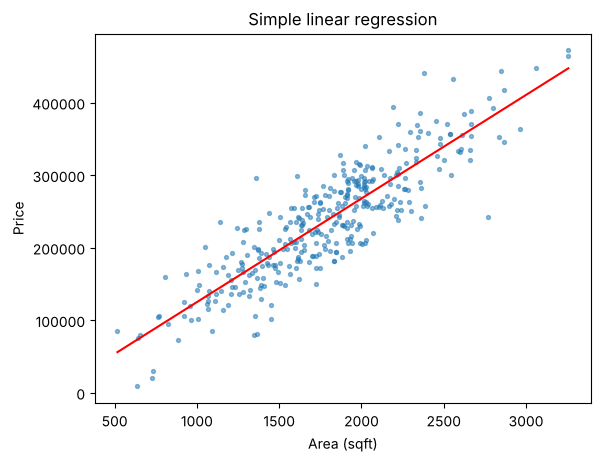

In [5]:
plt.scatter(X_tr['area_sqft'], y_tr, s=8, alpha=0.5)
xs = X_tr[['area_sqft']].sort_values('area_sqft')
plt.plot(xs, simple.predict(xs), color='red')
plt.xlabel('Area (sqft)')
plt.ylabel('Price')
plt.title('Simple linear regression')
plt.show()

Each extra square foot adds about 143 to the price. Area alone explains about 80% of the variation in price.

## Multiple linear regression: all features

In [6]:
multi = LinearRegression().fit(X_tr, y_tr)
print('R2 (validation), all features:', round(r2_score(y_val, multi.predict(X_val)), 3))
print('R2 (validation), area only   :', round(r2_score(y_val, simple.predict(X_val[['area_sqft']])), 3))

R2 (validation), all features: 0.914
R2 (validation), area only   : 0.8


Using all five features gives a better score than using area alone. The full evaluation is done on Day 7.